# Assignment 4: Diffusion and Energy-Based Models

He Xiao | UNI: hx2425  
GitHub: [HotcatX/API-test](https://github.com/HotcatX/API-test)

## Part I. Model Training and API Deployment

Two unconditional RGB image generators extend the existing FastAPI service:
a denoising diffusion probabilistic model (DDPM) and a convolutional energy
model (EBM). Both are trained on all 50,000 images in CIFAR-10's official
training split, at their native resolution of 32 x 32 (Krizhevsky, 2009). Labels are ignored.
Pixel values are normalized with `uint8 / 127.5 - 1`.

The API loads the included trained weights on CPU. It needs no training or
model download at startup. The earlier text, embedding, classifier, and GAN
endpoints remain available. This notebook reads the saved artifacts and
performs small inference and gradient checks; training is run separately.

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import json
import os
import sys
import time
import warnings

import torch
from PIL import Image
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", message="Using .*httpx.*starlette.testclient.* is deprecated.*")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "app/diffusion_model.py").is_file())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
torch.set_num_threads(min(2, torch.get_num_threads()))
from app.diffusion_model import load_diffusion, sinusoidal_embedding
from app.energy_model import load_energy_model, langevin_sample
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Project virtual environment:", Path(sys.prefix).resolve() == (ROOT / ".venv").resolve())

Python: 3.12.14
PyTorch: 2.8.0
Project virtual environment: True


### Diffusion implementation

A small UNet predicts Gaussian noise. It uses a 64-dimensional interleaved
sine/cosine timestep embedding, a learned time projection, GroupNorm/SiLU
residual blocks, two downsampling stages (32 -> 16 -> 8), and two upsampling
stages with skip connections. The final output has three channels. The
architecture is in `app/diffusion_model.py`; the training loop is in
`scripts/train_cifar10_diffusion.py`.

For each minibatch, sample a timestep and noise, form
$x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon$, and minimize
$\operatorname{mean}[(\epsilon_\theta(x_t,t)-\epsilon)^2]$.
Images and sampled noise do not require gradients; network parameters do.
The optimizer clears old gradients before every backward pass.

Sampling starts from Gaussian noise and uses all 100 reverse steps of a
cosine schedule, with a clipped clean-image estimate and the DDPM posterior
mean and variance. It uses the exponential moving average (EMA) of trained
weights under `torch.inference_mode()` (Ho et al., 2020; Nichol & Dhariwal, 2021).
Code indices 0 through 99 address the 100 noisy states; index 0 is the
first noisy state, whose final reverse update produces the clean estimate.

### Energy model and gradient control

The energy network uses four stride-2 convolutions with channels
16, 32, 64, and 64, SiLU activations, and a small fully connected head.
A fixed quadratic smoothness term penalizes differences between adjacent
pixels, so the total scalar energy per image is

$$E_\theta(x)=f_\theta(x)+0.002
  \sum_{(i,j)\in\mathcal A}(x_i-x_j)^2,$$

where $f_\theta$ is the trained CNN and $\mathcal A$ contains horizontal
and vertical adjacent pixel pairs within each RGB channel. Lower energy
is preferred. This explicit prior suppresses pixel-scale noise; it is not
a learned measure of object realism. `app/energy_model.py` contains the
network and sampler, and the same total energy is used in training and sampling.

Training alternates between two phases:

1. Freeze model parameters and run a finite Langevin-style chain on image
   tensors. Every step uses `x.detach().requires_grad_(True)` and
   `torch.autograd.grad(E(x).sum(), x)`. Pixel updates occur inside
   `torch.no_grad()`, so the graph is not retained across steps.
2. Re-enable parameter gradients, detach the sampled negatives, clear
   optimizer gradients, and update the energy network using

$$L=\operatorname{mean}E_\theta(x^+)
   -\operatorname{mean}E_\theta(\operatorname{stopgrad}(x^-))
   +0.1\left[\operatorname{mean}\big[E_\theta(x^+)^2\big]
             +\operatorname{mean}\big[E_\theta(x^-)^2\big]\right].$$

A replay buffer holds 2,048 negative images; 5% of initial states are
refreshed with uniform noise. Training uses 20 sampling steps. API
generation always starts from fresh uniform noise and uses 100 steps:

$$x_{k+1}=\operatorname{clip}_{[-1,1]}
\left(x_k-10\operatorname{clip}_{[-0.03,0.03]}\nabla_x E_\theta(x_k)
+0.005\xi_k\right),\qquad\xi_k\sim\mathcal N(0,I).$$

These drift, noise, clipping, and finite-chain settings implement practical
short-run sampling; they do not establish exact equilibrium draws from
$p(x)\propto\exp[-E_\theta(x)]$. Input-gradient tracking remains enabled
during API sampling, while all model weights stay frozen (Lippe, 2024).

In [2]:
# Check that input-gradient sampling changes images, not model weights.
energy = load_energy_model()
before = {name: value.clone() for name, value in energy.state_dict().items()}
initial = torch.rand(2, 3, 32, 32, generator=torch.Generator().manual_seed(99)) * 2 - 1
with torch.no_grad():
    sampled = langevin_sample(energy, initial, steps=3, noise_std=0)
assert not sampled.requires_grad and not torch.equal(sampled, initial)
assert all(torch.equal(before[name], value) for name, value in energy.state_dict().items())
assert all(not p.requires_grad and p.grad is None for p in energy.parameters())
print("EBM: image pixels updated; weights unchanged; parameter gradients absent.")

diffusion, schedule = load_diffusion()
with torch.inference_mode():
    predicted_noise = diffusion(torch.zeros(2, 3, 32, 32), torch.tensor([0, 50]))
assert predicted_noise.shape == (2, 3, 32, 32)
print("DDPM noise-prediction shape:", tuple(predicted_noise.shape))
print("Reverse diffusion steps:", schedule.timesteps)

EBM: image pixels updated; weights unchanged; parameter gradients absent.
DDPM noise-prediction shape: (2, 3, 32, 32)
Reverse diffusion steps: 100


### Recorded training and diagnostics

In [3]:
dm = json.loads((ROOT / "assignment4/diffusion_metrics.json").read_text())
em = json.loads((ROOT / "assignment4/energy_training_metrics.json").read_text())
dh = json.loads((ROOT / "assignment4/diffusion_history.json").read_text())
eh = json.loads((ROOT / "assignment4/energy_training_history.json").read_text())
for kind, metrics in (("diffusion", dm), ("energy", em)):
    actual = hashlib.sha256((ROOT / f"models/cifar10_{kind}.pt").read_bytes()).hexdigest()
    assert actual == metrics["checkpoint_sha256"]
rows = [
    ("Training images / epoch", dm["train_count"], em["train_count"]),
    ("Epochs", dm["epochs"], em["epochs"]),
    ("Parameters", dm["parameters"], em["parameter_count"]),
    ("Batch size", dm["batch_size"], em["batch_size"]),
    ("Optimizer", dm["optimizer"], em["optimizer"]),
    ("Initial learning rate", dm["learning_rate"], em["learning_rate"]),
    ("Training seed", dm["seed"], em["seed"]),
    ("Training device", dm["training_device"], em["device"]),
    ("Training seconds", round(dm["training_seconds"], 1), round(em["elapsed_seconds"], 1)),
]
display(Markdown("| Setting | DDPM | EBM |\n|---|---:|---:|\n" +
                 "\n".join(f"| {key} | {a} | {b} |" for key, a, b in rows)))
held = dm["held_out_denoising"]
print(f"DDPM training noise MSE: {dh[0]['epsilon_mse']:.5f} -> {dh[-1]['epsilon_mse']:.5f}")
print(f"Held-out noise MSE ({held['count']} test images): {held['epsilon_mse']:.5f}")
print(f"Zero-noise-prediction baseline MSE: {held['zero_predictor_mse']:.5f}")
diag = em["diagnostics"]
print(f"EBM mean energy, fresh noise: {diag['initial_noise_mean_energy']:.5f}")
print(f"EBM mean energy, generated: {diag['generated_mean_energy']:.5f}")
print("Both saved checkpoint hashes verified.")

| Setting | DDPM | EBM |
|---|---:|---:|
| Training images / epoch | 50000 | 50000 |
| Epochs | 20 | 8 |
| Parameters | 297043 | 77793 |
| Batch size | 128 | 128 |
| Optimizer | AdamW | Adam |
| Initial learning rate | 0.0003 | 0.0001 |
| Training seed | 42 | 42 |
| Training device | mps | mps |
| Training seconds | 624.3 | 415.3 |

DDPM training noise MSE: 0.26991 -> 0.06747
Held-out noise MSE (1024 test images): 0.06293
Zero-noise-prediction baseline MSE: 0.99992
EBM mean energy, fresh noise: 7.34238
EBM mean energy, generated: -0.07508
Both saved checkpoint hashes verified.


In [4]:
evidence = json.loads((ROOT / "assignment4/verification.json").read_text())
display(Markdown("| Verification | Observed result |\n|---|---|\n" +
    "\n".join(f"| {k} | {v} |" for k, v in evidence["checks"].items())))
ci_path = ROOT / "assignment4/ci_verification.json"
if ci_path.exists():
    ci = json.loads(ci_path.read_text())
    display(Markdown(f"GitHub Actions: [{ci['conclusion']}]({ci['run_url']})"))
    print("Verified runtime commit:", ci["commit"])

| Verification | Observed result |
|---|---|
| Local automated tests | 166 passed, 0 skipped |
| Numerical and autograd calculations | Passed in the project .venv |
| Local HTTP checks (new and existing API endpoints) | Passed |
| Seed replay, bounds, PNG shape, and gradient isolation | Passed |
| GitHub Actions Linux tests | Passed |
| Docker build, container startup, and HTTP inference | Passed on GitHub Actions |

GitHub Actions: [success](https://github.com/HotcatX/API-test/actions/runs/43549918790)

Verified runtime commit: 3e73a24de408d3a9f44c9239e82a2f35f2d2f50e


The final DDPM diagnostic uses the first 1,024 official test images after
training, with fixed noise and timesteps. No test image contributes to model
updates. Noise MSE measures denoising, and energy reduction measures the
sampler's objective; neither is a perceptual image-quality score. FID and
Inception Score were not measured. These compact models receive a limited
training budget, so samples may show color and texture without clearly
recognizable CIFAR-10 objects. Neither model accepts a class or text prompt.

### Generated images and API checks

The grids below are actual CPU API responses, using the first 16 samples
from seed 2026. They are not selected by visual quality. Each tile is a
native 32 x 32 RGB image, with a two-pixel gap.

Diffusion model: seed 2026

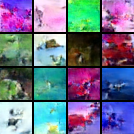

POST /generate-diffusion: HTTP 200, RGB 134 x 134, 2.49s


Energy model: seed 2026

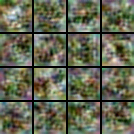

POST /generate-energy: HTTP 200, RGB 134 x 134, 0.42s
Invalid image counts rejected with HTTP 422.


In [5]:
from fastapi.testclient import TestClient
from app.main import app

client = TestClient(app)
for kind in ("diffusion", "energy"):
    started = time.perf_counter()
    response = client.post(f"/generate-{kind}", json={"count": 16, "seed": 2026})
    assert response.status_code == 200, response.text
    assert response.headers["x-seed"] == "2026"
    assert response.headers["x-image-count"] == "16"
    with Image.open(BytesIO(response.content)) as picture:
        assert picture.mode == "RGB" and picture.size == (134, 134)
        display(Markdown(f"{kind.capitalize()} model: seed 2026"))
        display(picture.copy())
    (ROOT / f"assignment4/api_{kind}_seed2026.png").write_bytes(response.content)
    print(f"POST /generate-{kind}: HTTP 200, RGB 134 x 134, {time.perf_counter()-started:.2f}s")
    assert client.post(f"/generate-{kind}", json={"count": 17}).status_code == 422
print("Invalid image counts rejected with HTTP 422.")

### Run and query the service

Build and start the included Docker deployment from the repository root:

```bash
docker build -t api-test:assignment4 .
docker run --rm -p 8000:80 api-test:assignment4
```

Open `http://localhost:8000/docs` for the interactive API. The root URL
retains the original Hello World response. Local development uses:

```bash
uv sync --locked --group notebook
uv run python -m ipykernel install --user --name api-test --display-name 'API-test (.venv)'
OMP_NUM_THREADS=2 MKL_NUM_THREADS=2 uv run uvicorn app.main:app --port 8000
```

Single-image requests return a 32 x 32 RGB PNG:

```bash
curl -f 'http://localhost:8000/generate-diffusion?seed=42' -o diffusion.png
curl -f 'http://localhost:8000/generate-energy?seed=42' -o energy.png
```

A JSON request returns a PNG grid:

```bash
curl -f -X POST http://localhost:8000/generate-diffusion \
  -H 'Content-Type: application/json' \
  -d '{"count":4,"seed":42}' -o diffusion-grid.png
curl -f -X POST http://localhost:8000/generate-energy \
  -H 'Content-Type: application/json' \
  -d '{"count":4,"seed":42}' -o energy-grid.png
```

`count` must be an integer from 1 to 16 (POST default: 4). The optional seed
is an integer from 0 to 4,294,967,295. `X-Seed`, `X-Image-Count`, and `X-Model`
identify the response. A returned random seed can be replayed using the same
count, checkpoint, device, and runtime. Invalid inputs return HTTP 422;
missing or incompatible trained weights return HTTP 503.

### Reproduce training and verification

```bash
uv run python scripts/train_cifar10_diffusion.py --epochs 20 --base-channels 16
uv run python scripts/train_cifar10_energy.py --epochs 8
OMP_NUM_THREADS=2 MKL_NUM_THREADS=2 uv run pytest -q
uv run python scripts/check_assignment4_theory.py
uv run python scripts/smoke_api.py --base-url http://127.0.0.1:8000
```

Training scripts use the project `.venv` and record settings, full-split
epoch counts, losses, and checkpoint hashes under `assignment4/`.
Training on different hardware may not be bitwise identical. API inference
uses private random generators and leaves the process-wide RNG unchanged.

## Part II. Building Blocks of a Diffusion Model

### Question 1: Sinusoidal timestep embedding

The embedding represents the timestep using sine and cosine functions at several frequencies. For an even embedding dimension $d$, let $k=0,\ldots,d/2-1$, use a maximum-period parameter $M=10000$, and define

$$
\omega_k=M^{-2k/d}.
$$

Using zero-based coordinates and interleaved sine/cosine pairs,

$$
e_{2k}(t)=\sin(t\omega_k),
\qquad
e_{2k+1}(t)=\cos(t\omega_k).
$$

Equivalently, the $i$-th coordinate is

$$
e_i(t)=
\begin{cases}
\sin\left(t/M^{i/d}\right), & i\text{ even},\\
\cos\left(t/M^{(i-1)/d}\right), & i\text{ odd}.
\end{cases}
$$

Angles are measured in radians. Higher-frequency coordinates change more rapidly with $t$, while lower-frequency coordinates change more slowly. This follows the sinusoidal positional-encoding construction of Vaswani et al. (2017). Here, $M$ is the conventional frequency-scale parameter; the actual sinusoid period is $2\pi/\omega_k$.

### Question 2: Eight-dimensional embedding at $t=1$

With $d=8$, the four frequency denominators are

$$
10000^{0/8}=1,\quad
10000^{2/8}=10,\quad
10000^{4/8}=100,\quad
10000^{6/8}=1000.
$$

Therefore, the angles are $1$, $0.1$, $0.01$, and $0.001$, and the vector is

$$
e(1)=
[\sin(1),\cos(1),\sin(0.1),\cos(0.1),
\sin(0.01),\cos(0.01),\sin(0.001),\cos(0.001)].
$$

Numerically, to nine decimal places,

```text
[0.841470985, 0.540302306, 0.099833417, 0.995004165,
 0.009999833, 0.999950000, 0.001000000, 0.999999500]
```

The ordering follows Question 1. An implementation that concatenates all cosines followed by all sines has the same values in a different order:

```text
[0.540302306, 0.995004165, 0.999950000, 0.999999500,
 0.841470985, 0.099833417, 0.009999833, 0.001000000]
```

### Question 3: Relation to transformer positional encoding

Both methods map a scalar index to a vector of sine and cosine values at different frequencies. In the original Transformer, the scalar is a token's position in a sequence; the encoding is added to token embeddings so the model can use sequence order (Vaswani et al., 2017). In a diffusion model, the scalar is the diffusion timestep or noise level; the embedding conditions the denoising network so it knows how much noise to remove. A timestep embedding may be passed through a learned projection and supplied to multiple UNet blocks (Ho et al., 2020). The key difference is what the index describes: token location versus denoising stage.

### Question 4: Bottleneck spatial resolution

Assuming each stride-2 block halves the height and width, the resolutions are

$$
64\times64\longrightarrow32\times32
\longrightarrow16\times16\longrightarrow8\times8.
$$

Thus,

$$
H_{\mathrm{bottleneck}}=W_{\mathrm{bottleneck}}
=\frac{64}{2^3}=8.
$$

The bottleneck spatial resolution is $8\times8$. For example, kernel size 3, stride 2, and padding 1 give this halving. The channel count depends on the architecture and is not specified by the question.

### Question 5: UNet output and diffusion loss

For the noise-prediction formulation, the UNet outputs an estimate $\epsilon_\theta(x_t,t)$ of the noise added to the image. Its output has the same shape as $x_t$; for RGB images, this is $(B,3,H,W)$.

Define $\alpha_t=1-\beta_t$ and $\bar\alpha_t=\prod_{s=1}^{t}\alpha_s$. To create a training input, sample a clean image $x_0$, a timestep $t$, and Gaussian noise $\epsilon\sim\mathcal N(0,I)$:

$$
x_t=\sqrt{\bar\alpha_t}\,x_0+
\sqrt{1-\bar\alpha_t}\,\epsilon.
$$

Train the UNet to predict the sampled $\epsilon$ using mean squared error:

$$
\mathcal L_{\mathrm{MSE}}
=\frac{1}{BCHW}\sum_{b,c,h,w}
\left[\epsilon_{bchw}-
\epsilon_\theta(x_t,t)_{bchw}\right]^2.
$$

This is the simplified DDPM noise-prediction objective, with an elementwise mean used in code (Ho et al., 2020):

```python
noise = torch.randn_like(x0)
alpha_bar_t = alpha_bar[t].view(-1, 1, 1, 1)
xt = alpha_bar_t.sqrt() * x0 + (1 - alpha_bar_t).sqrt() * noise
predicted_noise = model(xt, t)
loss = torch.nn.functional.mse_loss(predicted_noise, noise)
```

The prediction is noise, rather than the clean image directly. If needed, an estimate of the clean image is

$$
\hat x_0=
\frac{x_t-\sqrt{1-\bar\alpha_t}\,\epsilon_\theta(x_t,t)}
{\sqrt{\bar\alpha_t}}.
$$

## Part III. Building Blocks of an Energy Model

### Question 6: Basic gradient calculations

(a) The derivative of $y=x^2+3x$ is

$$
\frac{dy}{dx}=2x+3.
$$

At $x=2$, this gives $2(2)+3=7$. Running the supplied code prints

```text
x.grad = tensor([7.])
```

(b) If $x$ is created with `requires_grad=False`, none of the tensors in this particular expression require gradients. Thus, `y` has no autograd history, and `y.backward()` raises

```text
RuntimeError: element 0 of tensors does not require grad
and does not have a grad_fn
```

`x.grad` remains `None`. This conclusion concerns the supplied expression: if another input required gradients, an operation could still be tracked for that input.

(c) The default for `torch.tensor` is `requires_grad=False`. Gradients are therefore not tracked for the newly created tensor unless explicitly enabled (PyTorch Contributors, n.d.-a).

### Question 7: Introduce weights

(a) In the original code, `w = torch.tensor([1.0, 3.0])` uses the default `requires_grad=False`, so

```text
x.grad = tensor([7.])
w.grad = None
```

The values of `w` affect the calculation of $y$, but PyTorch has not been instructed to compute gradients with respect to `w`.

(b) For $y=w_0x^2+w_1x$, the partial derivatives are

$$
\frac{\partial y}{\partial w_0}=x^2,
\qquad
\frac{\partial y}{\partial w_1}=x.
$$

At $x=2$, they are $4$ and $2$. Enable gradient tracking before constructing the forward computation:

```python
import torch

x = torch.tensor([2.0], requires_grad=True)
w = torch.tensor([1.0, 3.0], requires_grad=True)
y = w[0] * x**2 + w[1] * x
y.backward()
print("x.grad =", x.grad)
print("w.grad =", w.grad)
```

Output:

```text
x.grad = tensor([7.])
w.grad = tensor([4., 2.])
```

If only weight gradients are needed, `x` can instead have `requires_grad=False`; `w.grad` is still `[4., 2.]`.

(c) Omitting the flag again gives `requires_grad=False`; using variable coefficients does not change this default (PyTorch Contributors, n.d.-a).

### Question 8: Breaking the graph

`z = y.detach()` removes the differentiable connection to `y` and `x`. The returned tensor does not require gradients (PyTorch Contributors, n.d.-c). Consequently, `w = z * 2` also has no autograd history, and `w.backward()` raises the same no-gradient-history error as in Question 6.

Keep the variable `z` but preserve its connection to `y`:

```python
x = torch.tensor([1.0], requires_grad=True)
y = x * 3
z = y.clone()  # A differentiable copy; z = y would also work.
w = z * 2
w.backward()
print("x.grad =", x.grad)
```

By the chain rule,

$$
\frac{dw}{dx}
=\frac{dw}{dz}\frac{dz}{dy}\frac{dy}{dx}
=2\cdot1\cdot3=6.
$$

The output is `x.grad = tensor([6.])`.

Using `z = y.detach().requires_grad_(True)` would make `z` a new leaf, but would not reconnect it to `x`: `z.grad` would be `[2.]`, while `x.grad` would remain `None`.

### Question 9: Gradient accumulation

The first backward pass adds $dy_1/dx=2$ to the empty gradient buffer. The second pass adds $dy_2/dx=3$ to the existing value:

$$
x.\mathrm{grad}:\quad 2\longrightarrow2+3=5.
$$

The supplied code prints

```text
After first backward: x.grad = tensor([2.])
After second backward: x.grad = tensor([5.])
```

PyTorch accumulates gradients in leaf tensors instead of replacing them on every backward pass (PyTorch Contributors, n.d.-b). To compute independent gradients, reset the buffer before the next backward pass:

```python
x = torch.tensor([1.0], requires_grad=True)
(x * 2).backward()
print("After first backward: x.grad =", x.grad)

x.grad = None  # Alternatively: x.grad.zero_()
(x * 3).backward()
print("After reset and second backward: x.grad =", x.grad)
```

The two outputs are `[2.]` and `[3.]`. In a training loop, the usual equivalent is `optimizer.zero_grad(set_to_none=True)` before `loss.backward()`. Accumulation can also be intentional, such as when combining gradients from several minibatches.

### Executed numerical and autograd checks

In [6]:
from scripts.check_assignment4_theory import run_checks
observed = run_checks()

PyTorch: 2.8.0
q2_embedding: [0.841470985, 0.540302306, 0.099833417, 0.995004165, 0.009999833, 0.99995, 0.001, 0.9999995]
q4_spatial_sizes: [64, 32, 16, 8]
q6_x_grad: [7.0]
q6_false_error: element 0 of tensors does not require grad and does not have a grad_fn
q6_default_requires_grad: False
q7_original_w_grad: None
q7_corrected_x_grad: [7.0]
q7_corrected_w_grad: [4.0, 2.0]
q8_detach_error: element 0 of tensors does not require grad and does not have a grad_fn
q8_corrected_x_grad: [6.0]
q8_detached_leaf_x_grad: None
q8_detached_leaf_z_grad: [2.0]
q9_first_grad: [2.0]
q9_second_grad: [5.0]
q9_after_reset_grad: [3.0]
All Assignment 4 theory checks passed.


## References

Ho, J., Jain, A., & Abbeel, P. (2020). Denoising diffusion probabilistic models. *Advances in Neural Information Processing Systems, 33*, 6840-6851. https://arxiv.org/abs/2006.11239

Krizhevsky, A. (2009). Learning multiple layers of features from tiny images. University of Toronto. https://cave.cs.toronto.edu/kriz/learning-features-2009-TR.pdf

Lippe, P. (2024). Tutorial 8: Deep energy-based generative models. UvA Deep Learning Tutorials. https://uvadlc-notebooks.readthedocs.io/en/latest/tutorial_notebooks/tutorial8/Deep_Energy_Models.html

Nichol, A. Q., & Dhariwal, P. (2021). Improved denoising diffusion probabilistic models. Proceedings of Machine Learning Research, 139, 8162-8171. https://proceedings.mlr.press/v139/nichol21a.html

PyTorch Contributors. (n.d.-a). *torch.tensor*. PyTorch 2.8 documentation. https://docs.pytorch.org/docs/2.8/generated/torch.tensor.html

PyTorch Contributors. (n.d.-b). *torch.Tensor.backward*. PyTorch 2.8 documentation. https://docs.pytorch.org/docs/2.8/generated/torch.Tensor.backward.html

PyTorch Contributors. (n.d.-c). *torch.Tensor.detach*. PyTorch 2.8 documentation. https://docs.pytorch.org/docs/2.8/generated/torch.Tensor.detach.html

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, L., & Polosukhin, I. (2017). Attention is all you need. *Advances in Neural Information Processing Systems, 30*. https://arxiv.org/abs/1706.03762